# 03 · Benchmarking NHS trusts: indirect standardisation, funnel plots and over-dispersion

**Question:** which hospital trusts have more emergency readmissions than their patient mix
would predict, and how confident can we be?

This is the method behind NHS England's readmission indicator and SHMI (the Summary Hospital-level
Mortality Indicator). We rebuild it from the published counts, check our version against NHS
England's own results, and then show why the standard version flags far too many trusts.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
import numpy as np
import pandas as pd

from nhsread import funnel as F
from nhsread import viz
from nhsread.config import BANDS, TIDY_FILE, YEARS
from nhsread.ingest.reader import providers

viz.set_style()
pd.set_option("display.width", 140)
tidy = pd.read_parquet(TIDY_FILE)
YEAR = "2024/25"
p = providers(tidy, YEAR)
eng_rate = 100 * p["num"].sum() / p["expected"].sum()  # sum(O)/sum(E) = 1 by construction, x England rate
E_RATE = 14.67  # England 2024/25: 948,836 / 6,467,596
print(f"{len(p)} NHS trusts in {YEAR}; England rate {E_RATE}%")

154 NHS trusts in 2024/25; England rate 14.67%


## 1. Indirect standardisation, rebuilt

A trust that treats more over-75s *should* have more readmissions. Indirect standardisation asks
how many readmissions the trust would have had if each of its patients had the **England rate for
their group**:

$$E_{\text{trust}} = \sum_{s} n_{\text{trust},s}\; p_{\text{England},s}, \qquad SR = O/E .$$

NHS England uses fine age and sex groups. The file gives us only three age bands x two sexes per
trust, so we can check how far six strata get us.

In [2]:
strata = ["<16", "16-74", "75+"]
eng = tidy[(tidy["breakdown"] == "England") & (tidy["year"] == YEAR) & (tidy["method"] == "Trend")
           & tidy["age"].isin(strata) & tidy["sex"].isin(["Male", "Female"])]
ref = (eng.assign(age=eng["age"].astype(str), sex=eng["sex"].astype(str))
       .set_index(["age", "sex"]).eval("num / den").rename("p_ref"))
print("England reference rates (%):")
print((100 * ref).round(2).unstack())

prov = tidy[(tidy["breakdown"] == "Provider") & (tidy["year"] == YEAR) & (tidy["method"] == "Trend")
            & tidy["age"].isin(strata) & tidy["sex"].isin(["Male", "Female"]) & tidy["level"].str.startswith("R")]
prov = prov.assign(age=prov["age"].astype(str), sex=prov["sex"].astype(str), stratum=list(zip(prov["age"].astype(str), prov["sex"].astype(str), strict=True)))
complete = prov.groupby("level")["den"].count().pipe(lambda s: s[s == 6].index)
prov = prov[prov["level"].isin(complete)]
ours = F.expected_counts(prov, ref.rename(index=None).set_axis(list(ref.index)), unit="level", stratum="stratum")
cmp = p.set_index("level")[["level_desc", "expected"]].join(ours.rename("our_expected"), how="inner")
print(f"\n{len(cmp)} trusts with all six strata published; correlation with NHS expected = "
      f"{np.corrcoef(cmp['expected'], cmp['our_expected'])[0, 1]:.4f}; "
      f"median ratio ours/NHS = {(cmp['our_expected'] / cmp['expected']).median():.3f}")

England reference rates (%):
sex    Female   Male
age                 
16-74   13.66  13.87
75+     17.12  18.74
<16     13.12  12.99

121 trusts with all six strata published; correlation with NHS expected = 0.9958; median ratio ours/NHS = 0.977


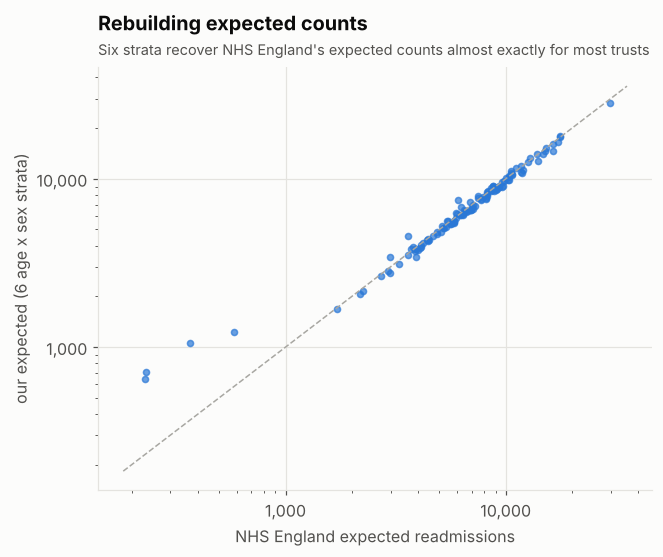

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(cmp["expected"], cmp["our_expected"], s=16, color=viz.BLUE, alpha=0.7)
lim = [cmp[["expected", "our_expected"]].min().min() * 0.8, cmp[["expected", "our_expected"]].max().max() * 1.2]
ax.plot(lim, lim, color=viz.GREY, ls="--", lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axis.set_minor_formatter(NullFormatter())
ax.set_xlabel("NHS England expected readmissions")
ax.set_ylabel("our expected (6 age x sex strata)")
ax.grid(True, which="major", axis="both")
ax.set_title("Rebuilding expected counts")
viz.subtitle(ax, "Six strata recover NHS England's expected counts almost exactly for most trusts")
viz.save(fig, "03_expected_check")
fig

Almost all trusts sit on the line. The few far off it are small specialist providers whose case
mix is unusual *within* an age band (for example a children's or cancer trust): finer case-mix
adjustment matters most exactly where patient mix is most unusual.

In a full model the reference rates $p_{\text{England},s}$ come from a **logistic regression** on
national data (as in notebook 02, or with diagnosis and comorbidity for SHMI). The expected count
for a trust is then the sum of every patient's predicted probability.

## 2. Confidence intervals and NHS banding, replicated

NHS England bands each trust by whether its 95% and 99.8% confidence interval for SR excludes 1
(the England rate). We use Byar's approximation to the exact Poisson interval.

In [4]:
p["our_band"] = F.band(p["num"], p["expected"])
lo, hi = F.ratio_ci(p["num"], p["expected"])
p["our_lci95"], p["our_uci95"] = lo * E_RATE, hi * E_RATE
agree = (p["our_band"] == p["band"]).mean()
print(f"agreement with published banding: {agree:.1%}  |  median |CI difference| "
      f"{np.median(np.abs(p['our_lci95'] - p['lci95'])):.2f} points")
pd.crosstab(p["band"], p["our_band"], rownames=["NHS England"], colnames=["ours"]).reindex(
    index=list(BANDS), columns=list(BANDS), fill_value=0)

agreement with published banding: 98.7%  |  median |CI difference| 0.03 points


ours,A1,A5,W,B5,B1
NHS England,,,,,
A1,43,0,0,0,0
A5,0,3,0,0,0
W,0,1,24,0,0
B5,0,0,0,12,1
B1,0,0,0,0,70


The few disagreements are trusts sitting right on a limit: published counts are rounded to the
nearest 5, which nudges their interval across the line.

## 3. The funnel plot

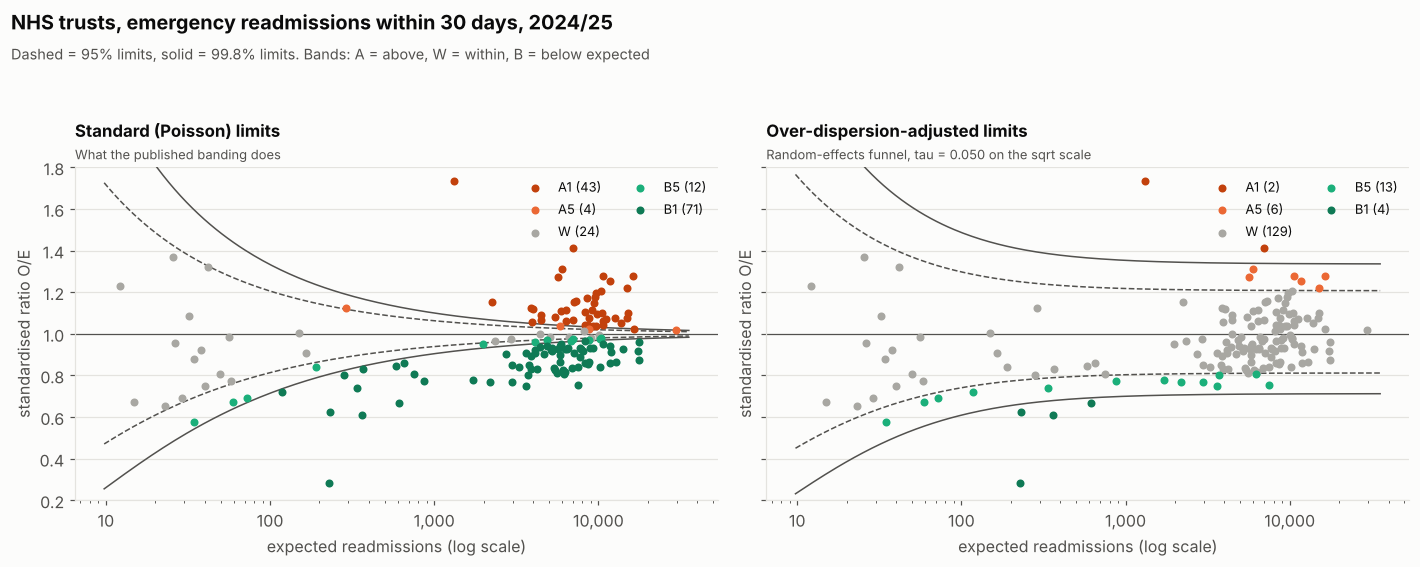

In [5]:
od = F.estimate_overdispersion(p["num"], p["expected"])
fr = F.funnel_frame(p["num"], p["expected"], tau2=od.tau2)


def funnel(ax, adjusted: bool, title: str, sub: str):
    bands = F.overdispersed_band(p["num"], p["expected"], od.tau2) if adjusted else p["our_band"]
    for b, col in viz.BAND_COLOURS.items():
        m = bands == b
        ax.scatter(p.loc[m, "expected"], p.loc[m, "sr"], s=18, color=col, label=f"{b} ({m.sum()})", zorder=3)
    pre = "od_" if adjusted else ""
    for z, ls in [("95", "--"), ("998", "-")]:
        ax.plot(fr["expected"], fr[f"{pre}lo{z}"], color=viz.TEXT_2, lw=1, ls=ls)
        ax.plot(fr["expected"], fr[f"{pre}hi{z}"], color=viz.TEXT_2, lw=1, ls=ls)
    ax.axhline(1, color=viz.TEXT_2, lw=0.8)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([10, 100, 1000, 10000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_ylim(0.2, 1.8)
    ax.set_xlabel("expected readmissions (log scale)")
    ax.set_ylabel("standardised ratio O/E")
    ax.legend(loc="upper right", fontsize=8.5, ncol=2)
    ax.set_title(title, fontsize=11, pad=20)
    ax.text(0, 1.015, sub, transform=ax.transAxes, fontsize=8.5, color=viz.TEXT_2, va="bottom")


fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
funnel(axes[0], False, "Standard (Poisson) limits", "What the published banding does")
funnel(axes[1], True, "Over-dispersion-adjusted limits", f"Random-effects funnel, tau = {np.sqrt(od.tau2):.3f} on the sqrt scale")
viz.fig_title(fig, f"NHS trusts, emergency readmissions within 30 days, {YEAR}",
              "Dashed = 95% limits, solid = 99.8% limits. Bands: A = above, W = within, B = below expected")
viz.save(fig, "03_funnels")
fig

**Left:** with Poisson limits, the funnel is so narrow for large trusts that most fall outside it.
**Right:** once we allow for genuine, unexplained between-trust variation, the limits widen and
only the truly unusual trusts stand out.

## 4. Measuring the over-dispersion (Spiegelhalter 2005, as used for SHMI)

1. Compute each trust's z-score on the square-root scale, $z = 2(\sqrt{O} - \sqrt{E})$, which is
   approximately N(0, 1) if only chance is at work.
2. Winsorise the most extreme 10% at each end (so the outliers we are looking for do not inflate
   the estimate).
3. The dispersion $\hat\phi$ is the mean of the squared winsorised z-scores; under pure chance it is 1.
4. If $\hat\phi$ is too large, estimate an additive between-trust variance $\hat\tau^2$ and widen the
   limits to $\big(1 \pm z_\alpha\sqrt{1/(4E) + \hat\tau^2}\big)^2$.

In [6]:
print(f"phi = {od.phi:.1f} (1 = chance only)  ->  over-dispersed: {od.overdispersed}")
print(f"tau = {np.sqrt(od.tau2):.4f} on the sqrt(SR) scale (about +/-{2 * 2 * np.sqrt(od.tau2):.0%} in SR at 2 sd)")
p["od_band"] = F.overdispersed_band(p["num"], p["expected"], od.tau2)
tab = pd.DataFrame({"published NHS banding": p["band"].value_counts(), "our Poisson banding": p["our_band"].value_counts(),
                    "over-dispersion adjusted": p["od_band"].value_counts()}).reindex(list(BANDS)).fillna(0).astype(int)
tab.loc["flagged at 99.8%"] = tab.loc[["A1", "B1"]].sum()
tab

phi = 62.6 (1 = chance only)  ->  over-dispersed: True
tau = 0.0504 on the sqrt(SR) scale (about +/-20% in SR at 2 sd)


,published NHS banding,our Poisson banding,over-dispersion adjusted
A1,43,43,2
A5,3,4,6
W,25,24,129
B5,13,12,13
B1,70,71,4
flagged at 99.8%,113,114,6


In 2024/25, published banding puts **113 of 154 trusts (73%)** outside the 99.8% limits. A 99.8%
limit should be crossed by chance about once in 500 trusts. After adjustment, **6 trusts** are
flagged at 99.8% and 25 at 95%: a list a regulator could actually act on.

This is not a critique of a mistake: the published bands answer "is this trust's rate different
from England's at all?", which with huge numbers is almost always yes. The adjusted bands answer
the more useful question: "is this trust unusual *compared with how much trusts normally differ*?"

## 5. Is the extra variation real or noise?
If it were noise, a trust's ratio this year would tell us little about next year. Year-to-year
rank correlation of SR for trusts with at least 5,000 discharges:

In [7]:
sr = (tidy[(tidy["breakdown"] == "Provider") & (tidy["method"] == "Snapshot") & (tidy["sex"] == "Persons")
           & tidy["level"].str.startswith("R") & (tidy["den"] > 5000)]
      .pivot_table(index="level", columns="year", values="sr"))
pairs = [(a, b) for a, b in zip(YEARS[:-1], YEARS[1:], strict=True)]
persist = pd.Series({f"{a} -> {b}": sr[[a, b]].dropna().corr(method="spearman").iloc[0, 1] for a, b in pairs})
persist.round(2).to_frame("Spearman rank correlation")

,Spearman rank correlation
2014/15 -> 2015/16,0.82
2015/16 -> 2016/17,0.81
2016/17 -> 2017/18,0.77
2017/18 -> 2018/19,0.78
2018/19 -> 2019/20,0.80
2019/20 -> 2020/21,0.82
2020/21 -> 2021/22,0.84
2021/22 -> 2022/23,0.86
2022/23 -> 2023/24,0.84
2023/24 -> 2024/25,0.86


Correlations of 0.77 to 0.86 from one year to the next: trusts that readmit more this year
readmit more next year. The over-dispersion is **systematic** (local services, coding, case mix the
age-sex adjustment misses), which is exactly why it must be modelled rather than ignored.

## 6. League tables mislead: shrinkage and rank uncertainty

A random-effects view also gives each trust a **shrunken** (empirical Bayes) estimate: small
trusts' noisy ratios are pulled towards 1 in proportion to how unreliable they are,

$$\sqrt{SR}^{\,\text{shrunk}} = 1 + \frac{\tau^2}{\tau^2 + 1/(4E)}\,(\sqrt{SR} - 1).$$

In [8]:
s2 = 1 / (4 * p["expected"])
wt = od.tau2 / (od.tau2 + s2)
p["sr_shrunk"] = (1 + wt * (np.sqrt(p["sr"]) - 1)) ** 2
post_sd = np.sqrt(wt * s2)  # posterior sd on the sqrt scale
p["shr_lo"] = (1 + wt * (np.sqrt(p["sr"]) - 1) - 1.96 * post_sd) ** 2
p["shr_hi"] = (1 + wt * (np.sqrt(p["sr"]) - 1) + 1.96 * post_sd) ** 2

rng = np.random.default_rng(1)
draws = (1 + wt.to_numpy() * (np.sqrt(p["sr"].to_numpy()) - 1) + rng.normal(size=(4000, len(p))) * post_sd.to_numpy()) ** 2
ranks = draws.argsort(axis=1).argsort(axis=1) + 1
p["rank_lo"], p["rank_hi"] = np.percentile(ranks, [2.5, 97.5], axis=0)
p["rank"] = p["sr_shrunk"].rank().astype(int)
print(f"median width of a trust's 95% rank interval: {np.median(p['rank_hi'] - p['rank_lo']):.0f} places out of {len(p)}")

median width of a trust's 95% rank interval: 19 places out of 154


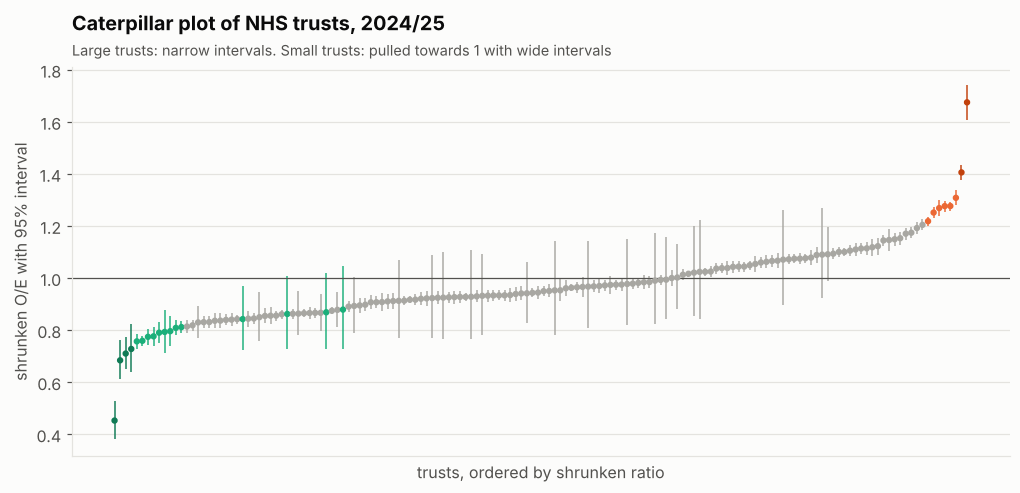

In [9]:
q = p.sort_values("sr_shrunk").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.6))
col = q["od_band"].map(viz.BAND_COLOURS)
ax.vlines(q.index, q["shr_lo"], q["shr_hi"], color=col, lw=1.2, alpha=0.8)
ax.scatter(q.index, q["sr_shrunk"], s=10, color=col, zorder=3)
ax.axhline(1, color=viz.TEXT_2, lw=0.8)
ax.set_xlabel("trusts, ordered by shrunken ratio")
ax.set_ylabel("shrunken O/E with 95% interval")
ax.set_xticks([])
ax.set_title(f"Caterpillar plot of NHS trusts, {YEAR}")
viz.subtitle(ax, "Large trusts: narrow intervals. Small trusts: pulled towards 1 with wide intervals")
viz.save(fig, "03_caterpillar")
fig

Even after shrinkage, the median trust's 95% interval for its rank spans about 19 places out of
154. Publishing a raw league table would present much of that uncertainty as performance.

## 7. The flagged trusts

In [10]:
flag = p[p["od_band"].isin(["A1", "A5", "B1", "B5"])].sort_values("sr", ascending=False)
flag[["level_desc", "den", "num", "expected", "sr", "sr_shrunk", "band", "od_band"]].rename(
    columns={"den": "discharges", "num": "observed", "band": "NHS band", "od_band": "adjusted band"}).round(3)

,level_desc,discharges,observed,expected,sr,sr_shrunk,NHS band,adjusted band
102,MIDLANDS PARTNERSHIP NHS FOUNDATION TRUST,6855.0,2275.0,1312.9,1.733,1.675,A1,A1
46,CHESTERFIELD ROYAL HOSPITAL NHS FOUNDATION TRUST,43555.0,9855.0,6978.1,1.412,1.406,A1,A1
9,ROYAL SURREY COUNTY HOSPITAL NHS FOUNDATION TRUST,42515.0,7865.0,5986.0,1.314,1.308,A1,A5
109,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,73635.0,13630.0,10653.6,1.279,1.277,A1,A5
43,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",101155.0,20910.0,16353.4,1.279,1.277,A1,A5
11,TORBAY AND SOUTH DEVON NHS FOUNDATION TRUST,35700.0,7220.0,5667.1,1.274,1.269,A1,A5
129,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,74880.0,14680.0,11705.5,1.254,1.252,A1,A5
65,UNIVERSITY HOSPITALS OF NORTH MIDLANDS NHS TRUST,98850.0,18325.0,15018.1,1.22,1.219,A1,A5
84,DARTFORD AND GRAVESHAM NHS TRUST,42590.0,5025.0,6210.2,0.809,0.812,B1,B5
49,JAMES PAGET UNIVERSITY HOSPITALS NHS FOUNDATIO...,25670.0,2990.0,3718.3,0.804,0.809,B1,B5


Several of the flagged trusts are specialist or non-acute providers (a children's trust, a
neurosciences trust, community and mental-health trusts), for whom age and sex are a poor
description of case mix. In
practice the next step would be a conversation with the trust, not a verdict: the funnel plot is a
**screening tool** for where to look.

## 8. Specialties

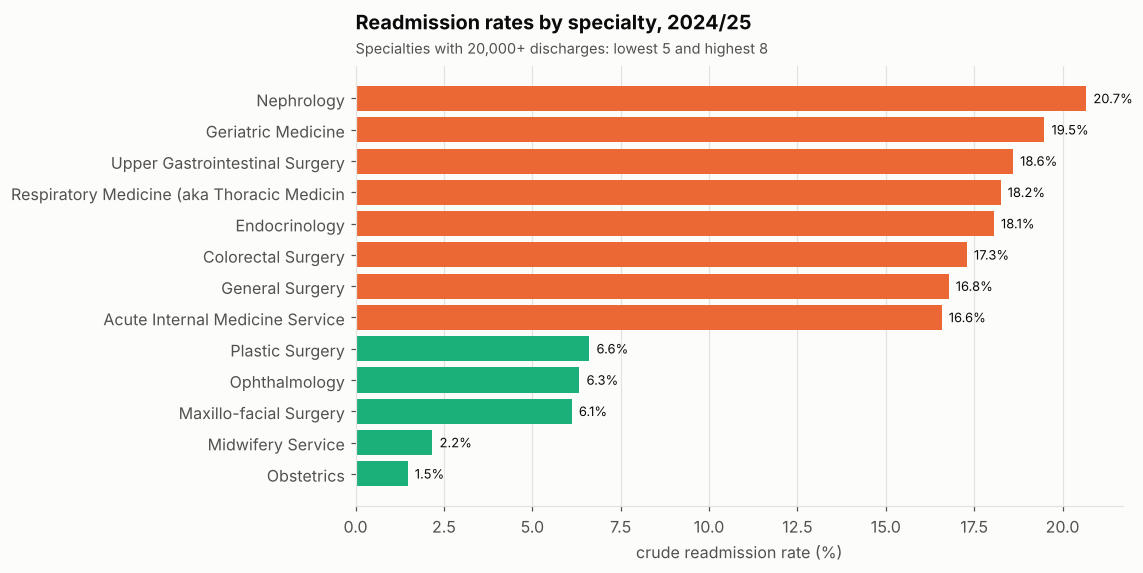

In [11]:
tf = tidy[(tidy["breakdown"] == "Treatment Function") & (tidy["year"] == YEAR) & (tidy["method"] == "Snapshot")
          & (tidy["sex"] == "Persons") & (tidy["den"] > 20000)]
tf = tf.assign(rate=tf["crude_rate"]).sort_values("rate")
show = pd.concat([tf.head(5), tf.tail(8)])
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(show["level_desc"].str.slice(0, 42), show["rate"], color=[viz.AQUA] * 5 + [viz.ORANGE] * 8)
for i, v in enumerate(show["rate"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("crude readmission rate (%)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title(f"Readmission rates by specialty, {YEAR}")
viz.subtitle(ax, "Specialties with 20,000+ discharges: lowest 5 and highest 8")
viz.save(fig, "03_specialties")
fig

Specialty differences dwarf the trust and deprivation effects: obstetrics discharges are rarely
followed by an emergency readmission, while nephrology, geriatric and upper-GI surgery patients
often are. Specialty mix is a big part of why "age and sex only" adjustment leaves trusts
over-dispersed.

**Takeaways**

* We rebuilt NHS England's indirect standardisation and banding from the published counts
  (expected-count correlation 0.996; banding agreement ~98%, limited only by rounding).
* Trust-level data are massively over-dispersed (phi about 60): the standard funnel flags 73% of
  trusts at 99.8%.
* An SHMI-style random-effects funnel cuts that to a handful, and the excess variation is
  persistent year to year, so it is real.
* Shrinkage and rank intervals show why raw league tables mislead.